In [ ]:

!pip -q install ucimlrepo


In [ ]:

import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch the official PhiUSIIL dataset
dataset = fetch_ucirepo(id=967)

# Combine input features and target labels
X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())


Dataset downloaded successfully!
Dataset shape: (235795, 55)

First 5 rows:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1


In [ ]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


Number of rows: 235795
Number of columns: 55

Column names:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Data types:
URL                 

In [ ]:

print("Target column names:")
print(y.columns.tolist())

target_column = y.columns[0]

print("\nClass counts:")
print(df[target_column].value_counts().sort_index())

print("\nClass percentages:")
print(
    df[target_column]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nLabel meaning:")
print("0 = Phishing")
print("1 = Legitimate")


Target column names:
['label']

Class counts:
label
0    100945
1    134850
Name: count, dtype: int64

Class percentages:
label
1    57.19
0    42.81
Name: proportion, dtype: float64

Label meaning:
0 = Phishing
1 = Legitimate


In [ ]:

print("Total missing values:", df.isnull().sum().sum())

print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nExact duplicate rows:", df.duplicated().sum())

if "URL" in df.columns:
    print("Duplicate URL values:", df["URL"].duplicated().sum())


Total missing values: 0

Columns with missing values:
Series([], dtype: int64)

Exact duplicate rows: 0
Duplicate URL values: 425


In [ ]:

# Find URLs that appear more than once
url_counts = df["URL"].value_counts()
repeated_urls = url_counts[url_counts > 1]

print("Number of distinct URLs appearing repeatedly:",
      len(repeated_urls))

print("Total rows belonging to repeated URLs:",
      repeated_urls.sum())

# Check whether repeated URLs have conflicting labels
label_counts_per_url = df.groupby("URL")["label"].nunique()

conflicting_urls = label_counts_per_url[
    label_counts_per_url > 1
]

print("URLs with conflicting labels:",
      len(conflicting_urls))

# Display examples, if any
if len(repeated_urls) > 0:
    print("\nExamples of repeated URLs:")
    display(
        df[df["URL"].isin(repeated_urls.index)]
        .sort_values("URL")
        .head(10)
    )


Number of distinct URLs appearing repeatedly: 425
Total rows belonging to repeated URLs: 850
URLs with conflicting labels: 0

Examples of repeated URLs:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
219489,http://2f3a.reicrut-chat.workers.dev/,37,2f3a.reicrut-chat.workers.dev,29,0,dev,27.903290,0.36,0.000961,0.051950,...,1,0,0,0,0,0,0,0,0,0
57609,http://2f3a.reicrut-chat.workers.dev/,36,2f3a.reicrut-chat.workers.dev,29,0,dev,27.903290,0.36,0.000961,0.051950,...,1,0,0,0,0,0,0,0,0,0
227564,http://34.149.138.117/,21,34.149.138.117,14,1,117,38.231293,0.40,0.000000,0.001404,...,0,1,0,4,1,5,48,0,9,0
27166,http://34.149.138.117/,22,34.149.138.117,14,1,117,38.231293,0.40,0.000000,0.001404,...,0,1,0,4,1,4,48,0,9,0
147448,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,62,595221.selcdn.ru,16,0,ru,27.442490,1.00,0.018013,0.039487,...,0,0,1,2,2,7,0,0,3,0
189978,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,63,595221.selcdn.ru,16,0,ru,27.442490,1.00,0.018013,0.039556,...,0,0,1,2,2,7,0,0,3,0
57315,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,63,595221.selcdn.ru,16,0,ru,27.442490,1.00,0.018013,0.039551,...,0,0,1,2,2,7,0,0,3,0
31955,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,62,595221.selcdn.ru,16,0,ru,27.442490,1.00,0.018013,0.039482,...,0,0,1,2,2,7,0,0,3,0
197956,http://91.239.125.28/postchs/sms.php,35,91.239.125.28,13,1,28,24.188408,0.40,0.000000,0.028501,...,0,0,1,1,1,1,0,0,0,0
126246,http://91.239.125.28/postchs/sms.php,36,91.239.125.28,13,1,28,24.188408,0.40,0.000000,0.028347,...,0,0,1,1,1,1,0,0,0,0


In [ ]:

candidate_features = [
    "IsHTTPS",
    "CharContinuationRate",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "NoOfAmpersandInURL",
    "ObfuscationRatio",
    "HasObfuscation",
    "IsDomainIP",
    "TLDLength",
    "NoOfQMarkInURL",
    "NoOfDegitsInURL",
    "URLLength",
    "NoOfLettersInURL",
    "DomainLength",
    "NoOfOtherSpecialCharsInURL",
    "LetterRatioInURL",
    "DegitRatioInURL",
    "SpacialCharRatioInURL"
]

missing_features = [
    feature for feature in candidate_features
    if feature not in df.columns
]

print("Candidate feature count:", len(candidate_features))
print("Features not found:", missing_features)

if not missing_features:
    print("\nAll candidate features exist in the dataset.")
    display(df[candidate_features].head())


Candidate feature count: 18
Features not found: []

All candidate features exist in the dataset.


,IsHTTPS,CharContinuationRate,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1.000000,1,0,0,0.0,0,0,3,0,0,31,18,24,1,0.581,0.0,0.032
1,1,0.666667,1,0,0,0.0,0,0,2,0,0,23,9,16,2,0.391,0.0,0.087
2,1,0.866667,2,0,0,0.0,0,0,2,0,0,29,15,22,2,0.517,0.0,0.069
3,1,1.000000,1,0,0,0.0,0,0,3,0,0,26,13,19,1,0.500,0.0,0.038
4,1,1.000000,1,0,0,0.0,0,0,3,0,0,33,20,26,1,0.606,0.0,0.030


In [ ]:

repeated_url_values = df[df["URL"].duplicated(keep=False)].copy()

print("Rows belonging to repeated URLs:",
      len(repeated_url_values))

print("Unique repeated URL strings:",
      repeated_url_values["URL"].nunique())

varying_columns = (
    repeated_url_values.groupby("URL")
    .nunique()
    .gt(1)
    .sum()
)

varying_columns = varying_columns[varying_columns > 0]

print("\nColumns that vary across repeated URLs:")
print(varying_columns.sort_values(ascending=False))


Rows belonging to repeated URLs: 850
Unique repeated URL strings: 425

Columns that vary across repeated URLs:
URLLength                     425
LetterRatioInURL              424
SpacialCharRatioInURL         407
NoOfOtherSpecialCharsInURL    289
DegitRatioInURL               250
URLCharProb                   136
NoOfLettersInURL              129
Title                          96
LargestLineLength              72
LineOfCode                     37
NoOfExternalRef                27
NoOfJS                         27
NoOfCSS                        22
URLSimilarityIndex             21
NoOfImage                      19
NoOfSelfRef                    16
IsResponsive                   13
URLTitleMatchScore             13
HasPasswordField               11
HasHiddenFields                 9
NoOfURLRedirect                 9
HasSubmitButton                 9
HasFavicon                      8
NoOfDegitsInURL                 7
HasTitle                        6
Robots                          4
Bank 

In [ ]:

# Keep the original dataset unchanged
df_clean = df.drop_duplicates(subset="URL", keep="first").copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Repeated URLs remaining:",
      df_clean["URL"].duplicated().sum())

print("\nClass distribution after removing repeated URLs:")
print(df_clean["label"].value_counts().sort_index())

print("\nClass percentages after cleaning:")
print(
    df_clean["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Original dataset shape: (235795, 55)
Cleaned dataset shape: (235370, 55)
Repeated URLs remaining: 0

Class distribution after removing repeated URLs:
label
0    100520
1    134850
Name: count, dtype: int64

Class percentages after cleaning:
label
1    57.29
0    42.71
Name: proportion, dtype: float64


In [ ]:

candidate_features = [
    "IsHTTPS",
    "CharContinuationRate",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "NoOfAmpersandInURL",
    "ObfuscationRatio",
    "HasObfuscation",
    "IsDomainIP",
    "TLDLength",
    "NoOfQMarkInURL",
    "NoOfDegitsInURL",
    "URLLength",
    "NoOfLettersInURL",
    "DomainLength",
    "NoOfOtherSpecialCharsInURL",
    "LetterRatioInURL",
    "DegitRatioInURL",
    "SpacialCharRatioInURL"
]

X = df_clean[candidate_features].copy()
y = df_clean["label"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing feature values:", X.isnull().sum().sum())
print("Missing target values:", y.isnull().sum())

print("\nTarget label counts:")
print(y.value_counts().sort_index())

print("\nFirst five feature rows:")
display(X.head())


Feature matrix shape: (235370, 18)
Target shape: (235370,)

Missing feature values: 0
Missing target values: 0

Target label counts:
label
0    100520
1    134850
Name: count, dtype: int64

First five feature rows:


,IsHTTPS,CharContinuationRate,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1.000000,1,0,0,0.0,0,0,3,0,0,31,18,24,1,0.581,0.0,0.032
1,1,0.666667,1,0,0,0.0,0,0,2,0,0,23,9,16,2,0.391,0.0,0.087
2,1,0.866667,2,0,0,0.0,0,0,2,0,0,29,15,22,2,0.517,0.0,0.069
3,1,1.000000,1,0,0,0.0,0,0,3,0,0,26,13,19,1,0.500,0.0,0.038
4,1,1.000000,1,0,0,0.0,0,0,3,0,0,33,20,26,1,0.606,0.0,0.030


In [ ]:

import re
import ipaddress
from urllib.parse import urlparse

def extract_url_features(url):
    url = str(url).strip()

    # Add a scheme when one is not provided
    if "://" not in url:
        url = "http://" + url

    parsed = urlparse(url)
    host = parsed.hostname or ""
    path_query = parsed.path + parsed.query + parsed.fragment

    # Identify whether the host is an IP address
    try:
        ipaddress.ip_address(host)
        is_ip = 1
    except ValueError:
        is_ip = 0

    # Approximate TLD and subdomain values from the hostname
    host_parts = host.split(".")
    tld = host_parts[-1] if len(host_parts) > 1 else ""
    subdomain_count = max(len(host_parts) - 2, 0)

    # Count URL characters
    url_length = len(url)
    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    # Percent-encoded characters, e.g. %20
    obfuscated_count = len(re.findall(r"%[0-9a-fA-F]{2}", url))

    # Return the features in the same order as the training list
    return {
        "IsHTTPS": int(parsed.scheme.lower() == "https"),
        "NoOfSubDomain": subdomain_count,
        "NoOfObfuscatedChar": obfuscated_count,
        "NoOfAmpersandInURL": url.count("&"),
        "ObfuscationRatio": obfuscated_count / max(url_length, 1),
        "HasObfuscation": int(obfuscated_count > 0 or "@" in url),
        "IsDomainIP": is_ip,
        "TLDLength": len(tld),
        "NoOfQMarkInURL": url.count("?"),
        "NoOfDegitsInURL": digits,
        "URLLength": url_length,
        "NoOfLettersInURL": letters,
        "DomainLength": len(host),
        "NoOfOtherSpecialCharsInURL": sum(
            not c.isalnum() for c in url
        ),
        "LetterRatioInURL": letters / max(url_length, 1),
        "DegitRatioInURL": digits / max(url_length, 1),
        "SpacialCharRatioInURL": sum(
            not c.isalnum() for c in url
        ) / max(url_length, 1)
    }

sample_url = "https://www.example.com/login?id=123"

sample_features = extract_url_features(sample_url)

display(pd.DataFrame([sample_features]))


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1,0,0,0.0,0,0,3,1,3,36,25,15,8,0.694444,0.083333,0.222222


In [ ]:

sample_url = "https://www.example.com/login?id=123"

print("Features extracted from URL:")
display(pd.DataFrame([extract_url_features(sample_url)]))

print("Feature count:", len(extract_url_features(sample_url)))
print("Feature names:")
print(list(extract_url_features(sample_url).keys()))

print("\nDataset feature names:")
print(candidate_features)


Features extracted from URL:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1,0,0,0.0,0,0,3,1,3,36,25,15,8,0.694444,0.083333,0.222222


Feature count: 17
Feature names:
['IsHTTPS', 'NoOfSubDomain', 'NoOfObfuscatedChar', 'NoOfAmpersandInURL', 'ObfuscationRatio', 'HasObfuscation', 'IsDomainIP', 'TLDLength', 'NoOfQMarkInURL', 'NoOfDegitsInURL', 'URLLength', 'NoOfLettersInURL', 'DomainLength', 'NoOfOtherSpecialCharsInURL', 'LetterRatioInURL', 'DegitRatioInURL', 'SpacialCharRatioInURL']

Dataset feature names:
['IsHTTPS', 'CharContinuationRate', 'NoOfSubDomain', 'NoOfObfuscatedChar', 'NoOfAmpersandInURL', 'ObfuscationRatio', 'HasObfuscation', 'IsDomainIP', 'TLDLength', 'NoOfQMarkInURL', 'NoOfDegitsInURL', 'URLLength', 'NoOfLettersInURL', 'DomainLength', 'NoOfOtherSpecialCharsInURL', 'LetterRatioInURL', 'DegitRatioInURL', 'SpacialCharRatioInURL']


In [ ]:
# Step 1: Extract the 17 URL-based features for every URL

feature_rows = []

for url in df_clean["URL"]:
    feature_rows.append(extract_url_features(url))

X_url = pd.DataFrame(feature_rows)

# Keep the original target labels
y_url = df_clean["label"].reset_index(drop=True)

# Reset feature-row indexes for clean alignment
X_url = X_url.reset_index(drop=True)

print("URL-based feature dataset created successfully!")
print("Feature dataset shape:", X_url.shape)
print("Target shape:", y_url.shape)

print("\nFirst 5 rows:")
display(X_url.head())

print("\nMissing feature values:", X_url.isnull().sum().sum())
print("Missing target values:", y_url.isnull().sum())
print("\nTarget distribution:")
print(y_url.value_counts().sort_index())

URL-based feature dataset created successfully!
Feature dataset shape: (235370, 17)
Target shape: (235370,)

First 5 rows:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1,0,0,0.0,0,0,3,0,0,32,27,24,5,0.843750,0.0,0.156250
1,1,1,0,0,0.0,0,0,2,0,0,24,18,16,6,0.750000,0.0,0.250000
2,1,2,0,0,0.0,0,0,2,0,0,30,24,22,6,0.800000,0.0,0.200000
3,1,1,0,0,0.0,0,0,3,0,0,27,22,19,5,0.814815,0.0,0.185185
4,1,1,0,0,0.0,0,0,3,0,0,34,29,26,5,0.852941,0.0,0.147059



Missing feature values: 0
Missing target values: 0

Target distribution:
label
0    100520
1    134850
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split

# Split the dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_url,
    y_url,
    test_size=0.20,
    random_state=42,
    stratify=y_url
)

print("Data splitting completed successfully!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining label distribution (%):")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting label distribution (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Data splitting completed successfully!
Training features: (188296, 17)
Testing features: (47074, 17)
Training labels: (188296,)
Testing labels: (47074,)

Training label distribution (%):
label
1    57.29
0    42.71
Name: proportion, dtype: float64

Testing label distribution (%):
label
1    57.29
0    42.71
Name: proportion, dtype: float64


In [ ]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

# Display a few scaled rows
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("\nFirst 5 rows of scaled training data:")
display(scaled_df.head())

print("\nMean of the first 5 scaled features:")
print(scaled_df.iloc[:, :5].mean().round(4))

print("\nStandard deviation of the first 5 scaled features:")
print(scaled_df.iloc[:, :5].std().round(4))


Feature scaling completed successfully!
Scaled training data shape: (188296, 17)
Scaled testing data shape: (47074, 17)

First 5 rows of scaled training data:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,0.530451,1.390394,-0.029156,-0.078265,-0.045155,-0.099584,-0.051444,0.394808,-0.152207,0.008067,1.323533,1.458905,0.170428,2.653023,-0.224832,-0.092493,0.560549
1,0.530451,-0.273840,-0.029156,-0.078265,-0.045155,-0.099584,-0.051444,-1.277424,-0.152207,-0.149151,-0.126522,-0.076227,0.060798,-0.247058,0.753156,-0.403247,-0.668784
2,-1.885188,-0.273840,-0.029156,-0.078265,-0.045155,-0.099584,-0.051444,0.394808,-0.152207,0.086676,-0.383790,-0.553824,-1.035500,-0.247058,-2.680098,1.853807,1.669722
3,0.530451,-0.273840,-0.029156,-0.078265,-0.045155,-0.099584,-0.051444,0.394808,-0.152207,-0.149151,-0.009582,0.094343,0.608947,-0.247058,1.074495,-0.403247,-1.245818
4,0.530451,1.390394,-0.029156,2.078460,-0.045155,10.041746,-0.051444,0.394808,5.000615,59.829385,134.705241,169.572963,2.253394,5.359765,1.146360,1.478865,-4.565830



Mean of the first 5 scaled features:
IsHTTPS               0.0
NoOfSubDomain         0.0
NoOfObfuscatedChar   -0.0
NoOfAmpersandInURL   -0.0
ObfuscationRatio      0.0
dtype: float64

Standard deviation of the first 5 scaled features:
IsHTTPS               1.0
NoOfSubDomain         1.0
NoOfObfuscatedChar    1.0
NoOfAmpersandInURL    1.0
ObfuscationRatio      1.0
dtype: float64


In [ ]:

!pip -q install xgboost

import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("All model libraries imported successfully!")


All model libraries imported successfully!


In [ ]:

# Define the first four models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Choose the appropriate data for each model
results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluate performance for class 1 (legitimate)
    # ROC-AUC measures ranking quality across thresholds
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0),
        "F1-Score": f1_score(y_test, y_pred, pos_label=0),
        "ROC-AUC": roc_auc_score(y_test, 1 - y_prob)
    }

    results.append(metrics)
    trained_models[name] = model

    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("Phishing Precision:", round(metrics["Precision"], 4))
    print("Phishing Recall:", round(metrics["Recall"], 4))
    print("Phishing F1-Score:", round(metrics["F1-Score"], 4))
    print("ROC-AUC:", round(metrics["ROC-AUC"], 4))

# Display the comparison table
results_df = pd.DataFrame(results)
display(results_df.round(4))



Training Logistic Regression...
Accuracy: 0.9879
Phishing Precision: 0.9898
Phishing Recall: 0.9817
Phishing F1-Score: 0.9857
ROC-AUC: 0.0041

Training Decision Tree...
Accuracy: 0.9952
Phishing Precision: 0.9978
Phishing Recall: 0.9908
Phishing F1-Score: 0.9943
ROC-AUC: 0.0043

Training Random Forest...
Accuracy: 0.9952
Phishing Precision: 0.9974
Phishing Recall: 0.9912
Phishing F1-Score: 0.9943
ROC-AUC: 0.0025

Training XGBoost...
Accuracy: 0.9933
Phishing Precision: 0.9944
Phishing Recall: 0.9899
Phishing F1-Score: 0.9921
ROC-AUC: 0.0025


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9879,0.9898,0.9817,0.9857,0.0041
1,Decision Tree,0.9952,0.9978,0.9908,0.9943,0.0043
2,Random Forest,0.9952,0.9974,0.9912,0.9943,0.0025
3,XGBoost,0.9933,0.9944,0.9899,0.9921,0.0025


In [ ]:

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

print("Training Linear SVM...")

svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

# Predict labels
svm_pred = svm_model.predict(X_test_scaled)

# Decision scores: higher scores favor class 1 (legitimate)
svm_scores = svm_model.decision_function(X_test_scaled)

# Save the trained model
trained_models["Linear SVM"] = svm_model

svm_metrics = {
    "Model": "Linear SVM",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "Precision": precision_score(y_test, svm_pred, pos_label=0),
    "Recall": recall_score(y_test, svm_pred, pos_label=0),
    "F1-Score": f1_score(y_test, svm_pred, pos_label=0),
    "ROC-AUC": roc_auc_score(y_test, -svm_scores)
}

# Add SVM to our existing results
results.append(svm_metrics)
results_df = pd.DataFrame(results)

print("\nLinear SVM results:")
display(pd.DataFrame([svm_metrics]).round(4))

print("\nComparison of all five models:")
display(
    results_df.sort_values(
        by="F1-Score", ascending=False
    ).reset_index(drop=True).round(4)
)


Training Linear SVM...

Linear SVM results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Linear SVM,0.9928,1.0,0.9831,0.9915,0.0046



Comparison of all five models:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9952,0.9974,0.9912,0.9943,0.0025
1,Decision Tree,0.9952,0.9978,0.9908,0.9943,0.0043
2,XGBoost,0.9933,0.9944,0.9899,0.9921,0.0025
3,Linear SVM,0.9928,1.0000,0.9831,0.9915,0.0046
4,Logistic Regression,0.9879,0.9898,0.9817,0.9857,0.0041



Logistic Regression
Confusion matrix:
[[19737   367]
 [  204 26766]]


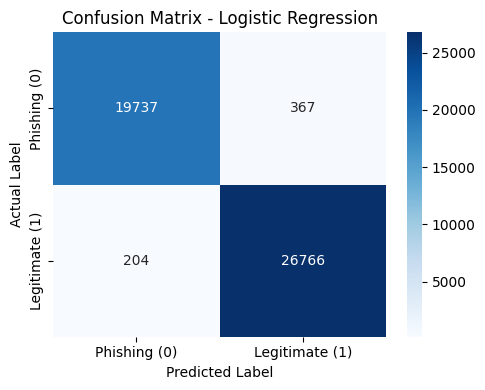


Decision Tree
Confusion matrix:
[[19919   185]
 [   43 26927]]


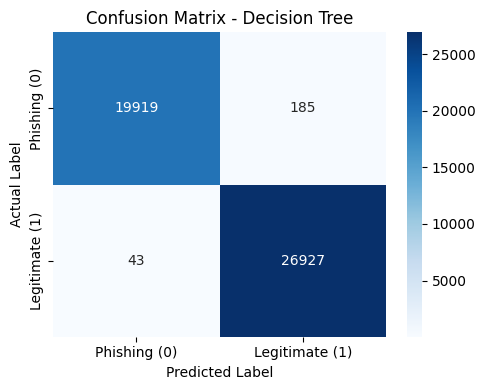


Random Forest
Confusion matrix:
[[19927   177]
 [   51 26919]]


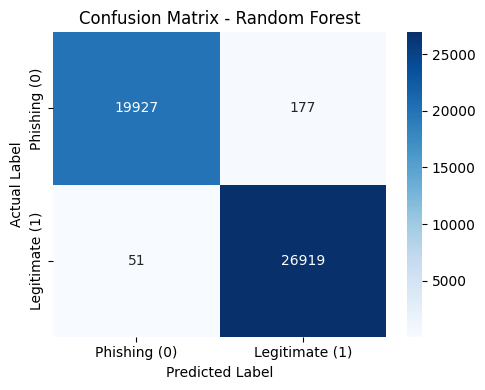


XGBoost
Confusion matrix:
[[19901   203]
 [  113 26857]]


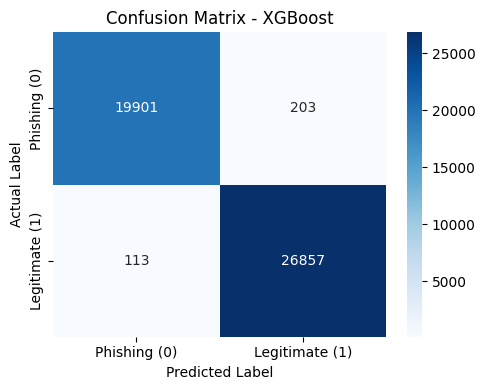


Linear SVM
Confusion matrix:
[[19764   340]
 [    0 26970]]


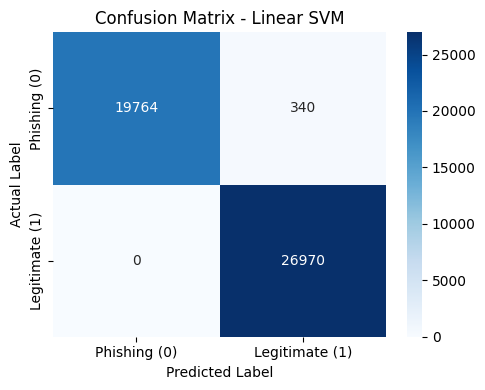

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Evaluate the models using the correct input representation
for name, model in trained_models.items():

    if name in ["Logistic Regression", "Linear SVM"]:
        predictions = model.predict(X_test_scaled)
    else:
        predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    print(f"\n{name}")
    print("Confusion matrix:")
    print(cm)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Phishing (0)", "Legitimate (1)"],
        yticklabels=["Phishing (0)", "Legitimate (1)"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()


In [ ]:

!pip -q install shap

import shap
import numpy as np
import pandas as pd

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")


SHAP version: 0.54.1
SHAP imported successfully!


In [ ]:

# Use a sample of the test data for SHAP
X_shap = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Build the SHAP TreeExplainer
explainer = shap.TreeExplainer(
    trained_models["Random Forest"]
)

# Calculate feature contributions
shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed!")
print("Sample shape:", X_shap.shape)
print("SHAP output type:", type(shap_values))


SHAP calculation completed!
Sample shape: (500, 17)
SHAP output type: <class 'numpy.ndarray'>


SHAP array shape: (500, 17, 2)


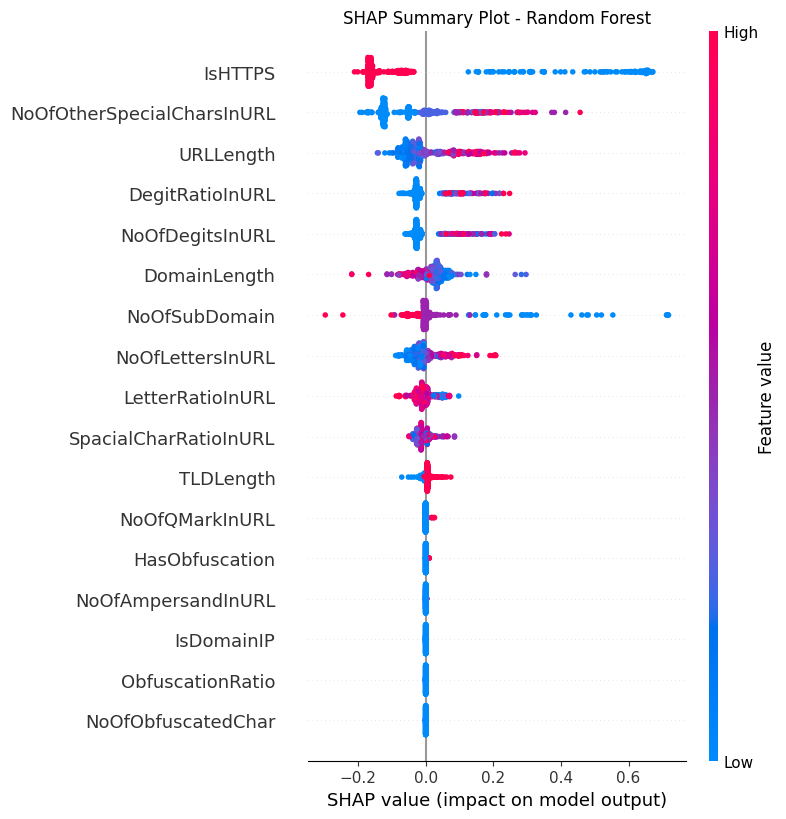

In [ ]:

import matplotlib.pyplot as plt
import shap
import numpy as np

# Check the SHAP output dimensions
print("SHAP array shape:", shap_values.shape)

# SHAP 0.52 may return (samples, features, classes)
# For our labels, class 0 means phishing.
if shap_values.ndim == 3:
    phishing_shap_values = shap_values[:, :, 0]
elif shap_values.ndim == 2:
    phishing_shap_values = shap_values
else:
    raise ValueError("Unexpected SHAP output dimensions.")

# Global feature importance summary
shap.summary_plot(
    phishing_shap_values,
    X_shap,
    show=False
)

plt.title("SHAP Summary Plot - Random Forest")
plt.tight_layout()
plt.show()


SHAP Feature Importance Ranking:


,Feature,Mean_Absolute_SHAP
0,IsHTTPS,0.222862
13,NoOfOtherSpecialCharsInURL,0.107316
10,URLLength,0.060790
15,DegitRatioInURL,0.044766
9,NoOfDegitsInURL,0.043470
12,DomainLength,0.038184
1,NoOfSubDomain,0.037642
11,NoOfLettersInURL,0.032383
14,LetterRatioInURL,0.018431
16,SpacialCharRatioInURL,0.014966


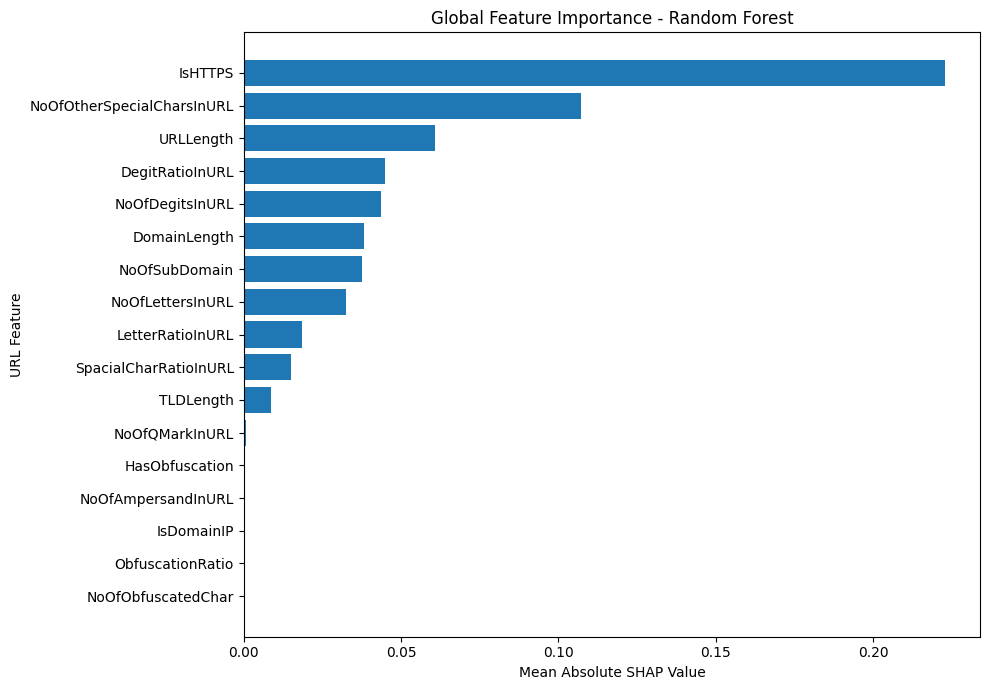

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Average absolute SHAP contribution across the 500 URLs
mean_abs_shap = np.abs(phishing_shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("SHAP Feature Importance Ranking:")
display(shap_importance.round(6))

# Plot all 17 features
plt.figure(figsize=(10, 7))

plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance["Mean_Absolute_SHAP"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("URL Feature")
plt.title("Global Feature Importance - Random Forest")
plt.tight_layout()
plt.show()


In [ ]:

# Select one URL from the 500 URLs already explained by SHAP
sample_index = 0

sample_url_features = X_shap.iloc[sample_index]
actual_label = y_test.loc[sample_url_features.name]

# Get the model's prediction for this URL
rf_model = trained_models["Random Forest"]
predicted_label = rf_model.predict(
    X_test.loc[[sample_url_features.name]]
)[0]

print("Selected test row:", sample_url_features.name)
print("Actual label:", actual_label)
print("Predicted label:", predicted_label)

print(
    "Actual class:",
    "Phishing" if actual_label == 0 else "Legitimate"
)

print(
    "Predicted class:",
    "Phishing" if predicted_label == 0 else "Legitimate"
)

print("\nFeatures of the selected URL:")
display(pd.DataFrame([sample_url_features]))



Selected test row: 76610
Actual label: 0
Predicted label: 0
Actual class: Phishing
Predicted class: Phishing

Features of the selected URL:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
76610,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,23.0,18.0,16.0,5.0,0.782609,0.0,0.217391


Generating SHAP waterfall plot...


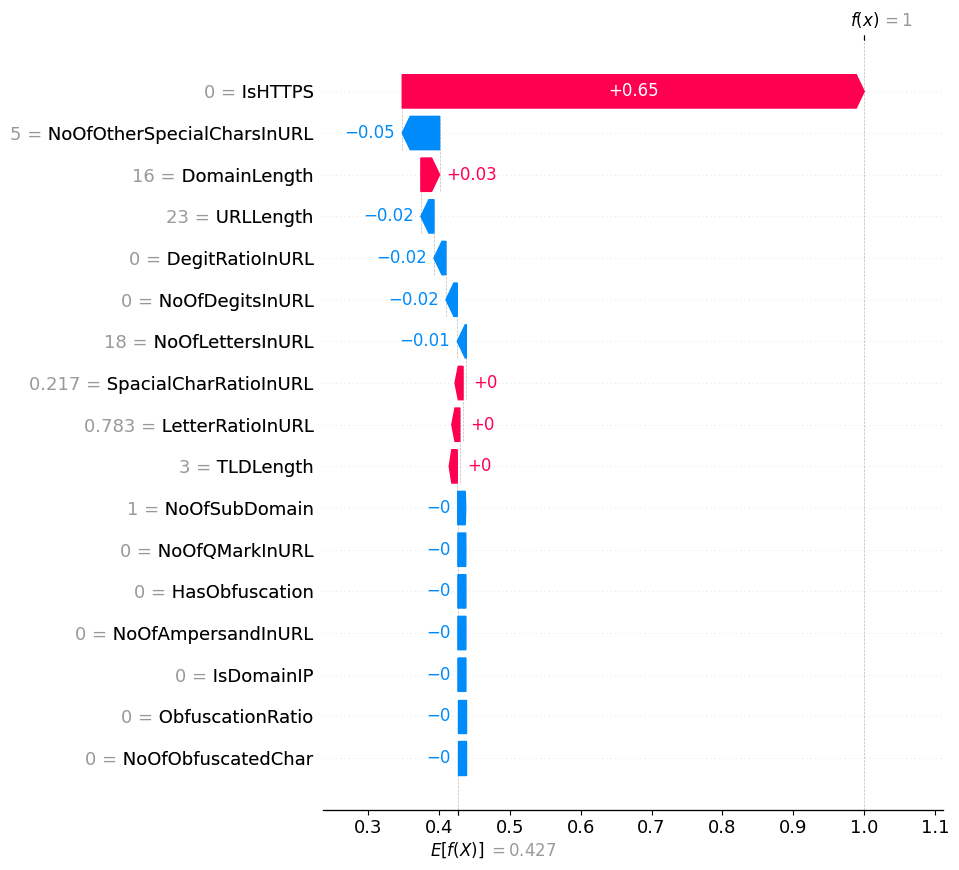

In [ ]:

# Get SHAP values for the selected URL and phishing class (class 0)
sample_shap_values = phishing_shap_values[sample_index]

# Expected model output for class 0
base_values = np.asarray(explainer.expected_value).reshape(-1)
phishing_base_value = base_values[0]

# Create the Explanation object required by the waterfall plot
waterfall_explanation = shap.Explanation(
    values=sample_shap_values,
    base_values=phishing_base_value,
    data=sample_url_features.values,
    feature_names=X_shap.columns.tolist()
)

print("Generating SHAP waterfall plot...")

shap.plots.waterfall(
    waterfall_explanation,
    max_display=17
)


In [ ]:

def predict_phishing_url(url):
    # Extract the same 17 features used during training
    features = extract_url_features(url)

    # Convert the dictionary to a DataFrame with the correct column order
    input_df = pd.DataFrame(
        [features],
        columns=X_train.columns
    )

    # Predict class and class probabilities
    prediction = trained_models["Random Forest"].predict(input_df)[0]
    probabilities = trained_models["Random Forest"].predict_proba(input_df)[0]

    phishing_probability = probabilities[
        list(trained_models["Random Forest"].classes_).index(0)
    ]

    legitimate_probability = probabilities[
        list(trained_models["Random Forest"].classes_).index(1)
    ]

    result = {
        "URL": url,
        "Prediction": (
            "PHISHING" if prediction == 0 else "LEGITIMATE"
        ),
        "Phishing Probability (%)": round(
            phishing_probability * 100, 2
        ),
        "Legitimate Probability (%)": round(
            legitimate_probability * 100, 2
        )
    }

    return result


# Test with an example URL
test_url = "https://www.example.com/login?id=123"

prediction_result = predict_phishing_url(test_url)

display(pd.DataFrame([prediction_result]))


,URL,Prediction,Phishing Probability (%),Legitimate Probability (%)
0,https://www.example.com/login?id=123,PHISHING,100.0,0.0


In [ ]:

test_urls = [
    "https://www.example.com/login?id=123",
    "http://example.com",
    "https://www.google.com",
    "http://192.168.1.1/login"
]

rf_model = trained_models["Random Forest"]

for url in test_urls:
    features = extract_url_features(url)

    input_df = pd.DataFrame(
        [features],
        columns=X_train.columns
    )

    prediction = rf_model.predict(input_df)[0]
    probabilities = rf_model.predict_proba(input_df)[0]

    probability_by_class = dict(
        zip(rf_model.classes_, probabilities)
    )

    print("\nURL:", url)
    print("Extracted features:")
    display(input_df)

    print(
        "Phishing probability:",
        round(probability_by_class[0] * 100, 2), "%"
    )
    print(
        "Legitimate probability:",
        round(probability_by_class[1] * 100, 2), "%"
    )
    print(
        "Prediction:",
        "PHISHING" if prediction == 0 else "LEGITIMATE"
    )



URL: https://www.example.com/login?id=123
Extracted features:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1,0,0,0.0,0,0,3,1,3,36,25,15,8,0.694444,0.083333,0.222222


Phishing probability: 100.0 %
Legitimate probability: 0.0 %
Prediction: PHISHING

URL: http://example.com
Extracted features:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,0,0,0,0,0.0,0,0,3,0,0,18,14,11,4,0.777778,0.0,0.222222


Phishing probability: 100.0 %
Legitimate probability: 0.0 %
Prediction: PHISHING

URL: https://www.google.com
Extracted features:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,1,1,0,0,0.0,0,0,3,0,0,22,17,14,5,0.772727,0.0,0.227273


Phishing probability: 0.21 %
Legitimate probability: 99.79 %
Prediction: LEGITIMATE

URL: http://192.168.1.1/login
Extracted features:


,IsHTTPS,NoOfSubDomain,NoOfObfuscatedChar,NoOfAmpersandInURL,ObfuscationRatio,HasObfuscation,IsDomainIP,TLDLength,NoOfQMarkInURL,NoOfDegitsInURL,URLLength,NoOfLettersInURL,DomainLength,NoOfOtherSpecialCharsInURL,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL
0,0,2,0,0,0.0,0,1,1,0,8,24,9,11,7,0.375,0.333333,0.291667


Phishing probability: 100.0 %
Legitimate probability: 0.0 %
Prediction: PHISHING


In [ ]:

# Diagnose the example URL
test_url = "https://www.example.com/login?id=123"

example_features = pd.DataFrame(
    [extract_url_features(test_url)],
    columns=X_train.columns
)

# Compare with the training data's feature ranges
diagnostics = pd.DataFrame({
    "Example_Value": example_features.iloc[0],
    "Training_Min": X_train.min(),
    "Training_Max": X_train.max(),
    "Training_Mean": X_train.mean()
})

diagnostics["Outside_Training_Range"] = (
    (diagnostics["Example_Value"] < diagnostics["Training_Min"]) |
    (diagnostics["Example_Value"] > diagnostics["Training_Max"])
)

print("Feature comparison:")
display(diagnostics.round(4))

# Inspect the model's predicted probabilities
rf_model = trained_models["Random Forest"]
probabilities = rf_model.predict_proba(example_features)[0]

print("\nModel classes:", rf_model.classes_)
print("Predicted probabilities:")
for cls, prob in zip(rf_model.classes_, probabilities):
    label_name = "Phishing" if cls == 0 else "Legitimate"
    print(f"{label_name}: {prob * 100:.2f}%")

# Check how strongly HTTPS correlates with the training labels
https_label_rates = (
    pd.DataFrame({
        "IsHTTPS": X_train["IsHTTPS"],
        "label": y_train
    })
    .groupby("IsHTTPS")["label"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
)

print("\nTraining label proportions by HTTPS status:")
display(https_label_rates.round(4))


Feature comparison:


,Example_Value,Training_Min,Training_Max,Training_Mean,Outside_Training_Range
IsHTTPS,1.0000,0.0000,1.0000,0.7804,False
NoOfSubDomain,1.0000,0.0000,10.0000,1.1645,False
NoOfObfuscatedChar,0.0000,0.0000,149.0000,0.0264,False
NoOfAmpersandInURL,0.0000,0.0000,50.0000,0.0363,False
ObfuscationRatio,0.0000,0.0000,0.2948,0.0001,False
HasObfuscation,0.0000,0.0000,1.0000,0.0098,False
IsDomainIP,0.0000,0.0000,1.0000,0.0026,False
TLDLength,3.0000,2.0000,13.0000,2.7639,False
NoOfQMarkInURL,1.0000,0.0000,4.0000,0.0295,False
NoOfDegitsInURL,3.0000,0.0000,2011.0000,1.8974,False



Model classes: [0 1]
Predicted probabilities:
Phishing: 100.00%
Legitimate: 0.00%

Training label proportions by HTTPS status:


label,0,1
IsHTTPS,,
0,1.0000,0.0000
1,0.2659,0.7341


In [ ]:

# 1. Check the original dataset's label distribution
print("Overall label distribution:")

display(
    df_clean["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Phishing", 1: "Legitimate"})
    .to_frame("Count")
)

# 2. Check label distribution by the original HTTPS feature
print("\nLabel proportions by original dataset HTTPS feature:")

display(
    pd.crosstab(
        df_clean["IsHTTPS"],
        df_clean["label"],
        normalize="index"
    ).round(4)
)

# 3. Display actual counts
print("\nCounts by HTTPS and label:")

display(
    pd.crosstab(
        df_clean["IsHTTPS"],
        df_clean["label"]
    )
)

# 4. Re-extract HTTPS status from each URL
extracted_https = df_clean["URL"].apply(
    lambda url: extract_url_features(url)["IsHTTPS"]
)

https_check = pd.DataFrame({
    "Dataset_IsHTTPS": df_clean["IsHTTPS"].astype(int).values,
    "Extracted_IsHTTPS": extracted_https.astype(int).values
})

print("\nHTTPS feature consistency:")
print(
    "Matching rows:",
    (https_check["Dataset_IsHTTPS"] ==
     https_check["Extracted_IsHTTPS"]).sum()
)

print(
    "Mismatching rows:",
    (https_check["Dataset_IsHTTPS"] !=
     https_check["Extracted_IsHTTPS"]).sum()
)


Overall label distribution:


,Count
label,
Phishing,100520
Legitimate,134850



Label proportions by original dataset HTTPS feature:


label,0,1
IsHTTPS,,
0,1.000,0.000
1,0.268,0.732



Counts by HTTPS and label:


label,0,1
IsHTTPS,,
0,51142,0
1,49378,134850



HTTPS feature consistency:
Matching rows: 234877
Mismatching rows: 493


In [ ]:

# Reset the index in both DataFrames
df_clean = df_clean.reset_index(drop=True)
https_check = https_check.reset_index(drop=True)

# Find rows where the HTTPS values disagree
mismatch_mask = (
    https_check["Dataset_IsHTTPS"] !=
    https_check["Extracted_IsHTTPS"]
)

# Get the row positions of mismatches
mismatch_indices = https_check.index[mismatch_mask]

# Display the mismatched rows
mismatch_details = pd.DataFrame({
    "URL": df_clean.loc[mismatch_indices, "URL"].values,
    "Label": df_clean.loc[mismatch_indices, "label"].values,
    "Dataset_IsHTTPS": https_check.loc[
        mismatch_indices, "Dataset_IsHTTPS"
    ].values,
    "Extracted_IsHTTPS": https_check.loc[
        mismatch_indices, "Extracted_IsHTTPS"
    ].values
})

print("Total HTTPS mismatches:", len(mismatch_details))

print("\nFirst 20 mismatches:")
display(mismatch_details.head(20))

print("\nMismatch counts by label:")
display(mismatch_details["Label"].value_counts().sort_index())


Total HTTPS mismatches: 493

First 20 mismatches:


,URL,Label,Dataset_IsHTTPS,Extracted_IsHTTPS
0,http://43.134.167.94/servicelogin?passive=1209...,0,1,0
1,http://43.128.92.128/servicelogin?passive=1209...,0,1,0
2,http://43.134.167.94/v3/signin/identifier?dsh=...,0,1,0
3,http://43.153.207.103/v3/signin/identifier?dsh...,0,1,0
4,http://43.156.0.130/servicelogin?passive=12096...,0,1,0
5,http://43.134.191.197/v3/signin/identifier?dsh...,0,1,0
6,http://43.128.92.128/interactivelogin?continue...,0,1,0
7,http://43.130.2.171/v3/signin/identifier?dsh=s...,0,1,0
8,http://43.156.237.181/v3/signin/identifier?dsh...,0,1,0
9,http://43.156.237.181/v3/signin/identifier?dsh...,0,1,0



Mismatch counts by label:


,count
Label,
0,493


In [ ]:

# Count labels for HTTP and HTTPS URLs using our extractor
https_label_check = pd.DataFrame({
    "Extracted_IsHTTPS": X_url["IsHTTPS"].values,
    "Label": y_url.values
})

print("Label distribution by extracted HTTPS feature:")
display(pd.crosstab(
    https_label_check["Extracted_IsHTTPS"],
    https_label_check["Label"],
    margins=True
))

print("\nLabel proportions within each HTTPS group:")
display(pd.crosstab(
    https_label_check["Extracted_IsHTTPS"],
    https_label_check["Label"],
    normalize="index"
).round(4))

# Check whether any HTTP URLs are labelled legitimate
http_legitimate = df_clean.loc[
    (X_url["IsHTTPS"].values == 0) &
    (y_url.values == 1),
    ["URL", "label"]
]

print("\nHTTP URLs labelled legitimate:", len(http_legitimate))
display(http_legitimate.head(10))


Label distribution by extracted HTTPS feature:


Label,0,1,All
Extracted_IsHTTPS,,,
0,51635,0,51635
1,48885,134850,183735
All,100520,134850,235370



Label proportions within each HTTPS group:


Label,0,1
Extracted_IsHTTPS,,
0,1.0000,0.0000
1,0.2661,0.7339



HTTP URLs labelled legitimate: 0


,URL,label


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)
import pandas as pd

# Use the same split for both experiments
X_train_cmp, X_test_cmp, y_train_cmp, y_test_cmp = train_test_split(
    X_url, y_url,
    test_size=0.20,
    random_state=42,
    stratify=y_url
)

# Model A: use all 17 features
rf_all = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_all.fit(X_train_cmp, y_train_cmp)
pred_all = rf_all.predict(X_test_cmp)

# Model B: remove IsHTTPS
X_train_no_https = X_train_cmp.drop(columns=["IsHTTPS"])
X_test_no_https = X_test_cmp.drop(columns=["IsHTTPS"])

rf_no_https = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_no_https.fit(X_train_no_https, y_train_cmp)
pred_no_https = rf_no_https.predict(X_test_no_https)

# Compare performance; class 0 means phishing
comparison = []

for name, predictions in [
    ("Random Forest - All 17 features", pred_all),
    ("Random Forest - Without IsHTTPS", pred_no_https)
]:
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_cmp, predictions),
        "Phishing Precision": precision_score(
            y_test_cmp, predictions, pos_label=0, zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_test_cmp, predictions, pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_test_cmp, predictions, pos_label=0, zero_division=0
        )
    })

print("Performance comparison:")
display(pd.DataFrame(comparison).round(4))

print("\nConfusion matrix - All 17 features")
print("Rows = actual labels [phishing, legitimate]")
print("Columns = predicted labels [phishing, legitimate]")
print(confusion_matrix(y_test_cmp, pred_all, labels=[0, 1]))

print("\nConfusion matrix - Without IsHTTPS")
print(confusion_matrix(y_test_cmp, pred_no_https, labels=[0, 1]))


In [ ]:

# Check for exact URL overlap between training and testing sets

train_urls = set(
    df_clean.loc[X_train_cmp.index, "URL"]
)

test_urls = set(
    df_clean.loc[X_test_cmp.index, "URL"]
)

overlap = train_urls.intersection(test_urls)

print("Unique training URLs:", len(train_urls))
print("Unique testing URLs:", len(test_urls))
print("Exact URL overlap:", len(overlap))


In [ ]:

from urllib.parse import urlparse

def get_domain(url):
    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url

    return (urlparse(url).hostname or "").lower()

# Get domains corresponding to training and testing rows
train_domains = set(
    df_clean.loc[X_train_cmp.index, "URL"].apply(get_domain)
)

test_domains = set(
    df_clean.loc[X_test_cmp.index, "URL"].apply(get_domain)
)

common_domains = train_domains.intersection(test_domains)

print("Unique training domains:", len(train_domains))
print("Unique testing domains:", len(test_domains))
print("Domains appearing in both sets:", len(common_domains))

print("\nExample overlapping domains:")
print(list(sorted(common_domains))[:20])


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
import pandas as pd

# Use the same URL rows and labels as before
groups = df_clean["URL"].apply(get_domain)

# Split by domain so a domain cannot occur in both partitions
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X_url, y_url, groups=groups)
)

X_train_domain = X_url.iloc[train_idx]
X_test_domain = X_url.iloc[test_idx]
y_train_domain = y_url.iloc[train_idx]
y_test_domain = y_url.iloc[test_idx]

print("Training rows:", len(X_train_domain))
print("Testing rows:", len(X_test_domain))
print(
    "Shared domains:",
    len(
        set(groups.iloc[train_idx]) &
        set(groups.iloc[test_idx])
    )
)

# Train Random Forest using all 17 features
rf_domain = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_domain.fit(X_train_domain, y_train_domain)
pred_domain = rf_domain.predict(X_test_domain)

print("\nDomain-separated evaluation:")
print("Accuracy:", round(accuracy_score(y_test_domain, pred_domain), 4))
print(
    "Phishing precision:",
    round(precision_score(y_test_domain, pred_domain, pos_label=0), 4)
)
print(
    "Phishing recall:",
    round(recall_score(y_test_domain, pred_domain, pos_label=0), 4)
)
print(
    "Phishing F1:",
    round(f1_score(y_test_domain, pred_domain, pos_label=0), 4)
)

print("\nConfusion matrix (actual rows, predicted columns; labels [0, 1]):")
print(confusion_matrix(y_test_domain, pred_domain, labels=[0, 1]))


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import pandas as pd

# Model A: all 17 features
model_all_domain = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model_all_domain.fit(X_train_domain, y_train_domain)
pred_all_domain = model_all_domain.predict(X_test_domain)

# Model B: remove IsHTTPS
model_no_https_domain = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model_no_https_domain.fit(
    X_train_domain.drop(columns=["IsHTTPS"]),
    y_train_domain
)
pred_no_https_domain = model_no_https_domain.predict(
    X_test_domain.drop(columns=["IsHTTPS"])
)

comparison_domain = []

for name, predictions in [
    ("All 17 features", pred_all_domain),
    ("Without IsHTTPS", pred_no_https_domain)
]:
    comparison_domain.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_domain, predictions),
        "Phishing Precision": precision_score(
            y_test_domain, predictions, pos_label=0, zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_test_domain, predictions, pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_test_domain, predictions, pos_label=0, zero_division=0
        )
    })

display(pd.DataFrame(comparison_domain).round(4))


In [ ]:

# Verify the model's input features match the URL extractor

test_url = "https://www.example.com/login?id=123"

test_features = extract_url_features(test_url)
test_input = pd.DataFrame([test_features])

print("Number of extracted features:", len(test_features))
print("Number of model features:", len(model_all_domain.feature_names_in_))

print("\nMissing model features:")
print(set(model_all_domain.feature_names_in_) - set(test_input.columns))

print("\nUnexpected extracted features:")
print(set(test_input.columns) - set(model_all_domain.feature_names_in_))

print("\nFeature input shape:", test_input.shape)
print("Model prediction:", model_all_domain.predict(test_input)[0])
print("Class probabilities:", model_all_domain.predict_proba(test_input)[0])


In [ ]:

!pip -q install shap

import shap
import matplotlib.pyplot as plt

# Use a small sample from the domain-separated test set
X_shap_domain = X_test_domain.sample(
    n=min(200, len(X_test_domain)),
    random_state=42
)

# Explain the selected Random Forest model
explainer_domain = shap.TreeExplainer(model_all_domain)
shap_values_domain = explainer_domain.shap_values(X_shap_domain)

print("SHAP output type:", type(shap_values_domain))
print("SHAP output shape:", getattr(shap_values_domain, "shape", None))

print("\nModel classes:", model_all_domain.classes_)
print("Class 0 = Phishing")
print("Class 1 = Legitimate")


In [ ]:

# Select SHAP values for class 0: Phishing
phishing_shap_domain = shap_values_domain[:, :, 0]

print("Phishing SHAP shape:", phishing_shap_domain.shape)

# Global feature importance plot
shap.summary_plot(
    phishing_shap_domain,
    X_shap_domain,
    plot_type="bar",
    show=False
)

plt.title("Feature Importance for Phishing Detection")
plt.tight_layout()
plt.show()


In [ ]:

# SHAP beeswarm plot for the phishing class (class 0)

shap.summary_plot(
    phishing_shap_domain,
    X_shap_domain,
    plot_type="dot",
    show=False
)

plt.title("SHAP Summary: Feature Impact on Phishing Predictions")
plt.tight_layout()
plt.show()


Actual label: Legitimate
Predicted label: Legitimate
Phishing probability: 0.0043
Legitimate probability: 0.9957


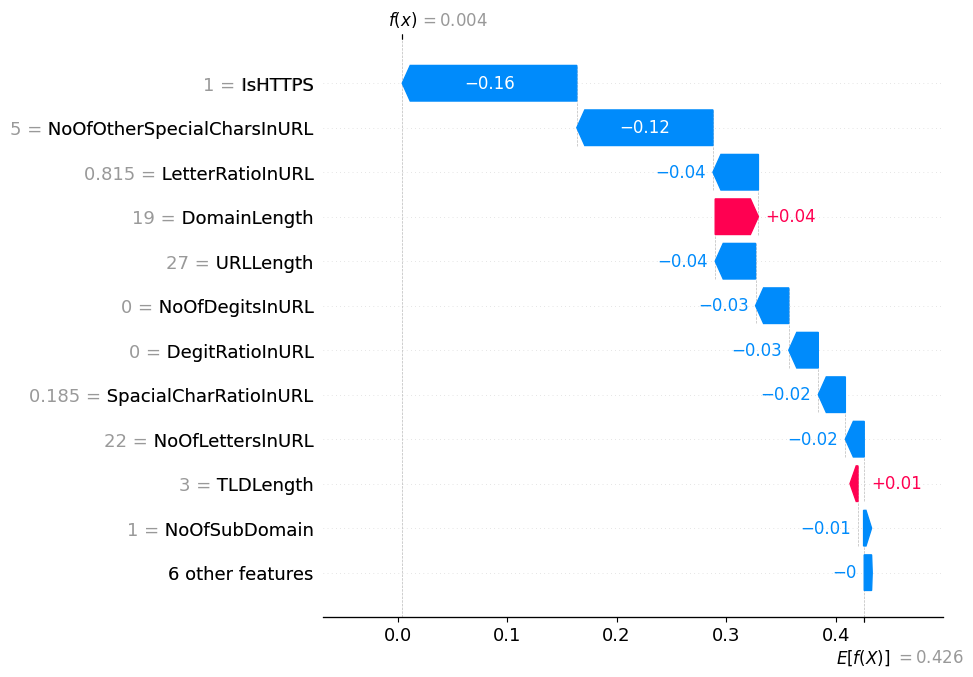

In [ ]:

import numpy as np
import shap
import matplotlib.pyplot as plt

# Select one URL from the domain-separated test set
sample_position = 0
sample_features = X_test_domain.iloc[[sample_position]]
actual_label = y_test_domain.iloc[sample_position]

# Get the prediction and probabilities
predicted_label = int(model_all_domain.predict(sample_features)[0])
probabilities = model_all_domain.predict_proba(sample_features)[0]

print("Actual label:", "Phishing" if actual_label == 0 else "Legitimate")
print("Predicted label:", "Phishing" if predicted_label == 0 else "Legitimate")
print("Phishing probability:", round(float(probabilities[0]), 4))
print("Legitimate probability:", round(float(probabilities[1]), 4))

# Explain this sample using SHAP
sample_shap = explainer_domain(sample_features)

# Select class 0 (phishing) from the last output dimension
sample_shap_phishing = shap.Explanation(
    values=sample_shap.values[0, :, 0],
    base_values=sample_shap.base_values[0, 0],
    data=sample_features.iloc[0].values,
    feature_names=sample_features.columns.tolist()
)

shap.plots.waterfall(sample_shap_phishing, max_display=12)


In [ ]:

!pip -q install gradio


In [ ]:

import pandas as pd

def predict_url_for_dashboard(url):
    # Check whether the user entered a URL
    if not url or not str(url).strip():
        return "Please enter a URL.", 0.0, 0.0

    try:
        # Extract the 17 features
        features = extract_url_features(url)

        # Arrange features in the exact order expected by the model
        input_df = pd.DataFrame([features])
        input_df = input_df[model_all_domain.feature_names_in_]

        # Predict the class
        prediction = int(model_all_domain.predict(input_df)[0])

        # Obtain probabilities: classes [0, 1]
        probabilities = model_all_domain.predict_proba(input_df)[0]
        phishing_probability = float(probabilities[0])
        legitimate_probability = float(probabilities[1])

        if prediction == 0:
            result = "⚠️ Model prediction: PHISHING"
        else:
            result = "✅ Model prediction: LEGITIMATE"

        return (
            result,
            round(phishing_probability, 4),
            round(legitimate_probability, 4)
        )

    except Exception as error:
        return f"Could not process this URL: {error}", 0.0, 0.0


# Test the function before connecting it to Gradio
predict_url_for_dashboard("https://www.google.com")


In [ ]:

import gradio as gr

with gr.Blocks(title="AI Phishing URL Detector") as demo:

    gr.Markdown("# 🔐 AI-Powered Phishing URL Detection")
    gr.Markdown(
        "Enter a URL to receive a machine-learning prediction "
        "and estimated class probabilities."
    )

    url_input = gr.Textbox(
        label="Enter URL",
        placeholder="Example: https://www.example.com/login",
        lines=1
    )

    predict_button = gr.Button("Check URL", variant="primary")

    prediction_output = gr.Textbox(
        label="Prediction",
        interactive=False
    )

    phishing_output = gr.Number(
        label="Phishing Probability (0–1)",
        precision=4
    )

    legitimate_output = gr.Number(
        label="Legitimate Probability (0–1)",
        precision=4
    )

    predict_button.click(
        fn=predict_url_for_dashboard,
        inputs=url_input,
        outputs=[
            prediction_output,
            phishing_output,
            legitimate_output
        ]
    )

    gr.Markdown(
        "**Disclaimer:** This tool provides model-based estimates, "
        "not definitive proof that a URL is safe or malicious. "
        "Do not enter passwords or other sensitive information."
    )

demo.launch(share=True, debug=True)


In [ ]:

import pandas as pd
import shap
import matplotlib.pyplot as plt

def explain_url(url):
    features = extract_url_features(url)
    input_df = pd.DataFrame([features])
    input_df = input_df[model_all_domain.feature_names_in_]

    # Explain this URL using the selected model
    explanation = explainer_domain(input_df)

    # Select the phishing class (class 0)
    phishing_values = explanation.values[0, :, 0]
    base_value = explanation.base_values[0, 0]

    shap_explanation = shap.Explanation(
        values=phishing_values,
        base_values=base_value,
        data=input_df.iloc[0].values,
        feature_names=input_df.columns.tolist()
    )

    return shap_explanation

# Test the explanation
test_explanation = explain_url("https://www.google.com")

print("Number of features explained:", len(test_explanation.values))
print("Top 5 features by absolute SHAP contribution:")

top_indices = (
    abs(test_explanation.values)
).argsort()[::-1][:5]

for index in top_indices:
    print(
        test_explanation.feature_names[index],
        "→",
        round(float(test_explanation.values[index]), 4)
    )

shap.plots.waterfall(test_explanation, max_display=10)


In [ ]:

import gradio as gr
import pandas as pd
import shap
import matplotlib.pyplot as plt

def predict_with_shap(url):
    if not url or not str(url).strip():
        return (
            "Please enter a URL.",
            {"Phishing": 0.0, "Legitimate": 0.0},
            None
        )

    try:
        # Extract features in the model's expected order
        features = extract_url_features(url)
        input_df = pd.DataFrame([features])
        input_df = input_df[model_all_domain.feature_names_in_]

        # Prediction and class probabilities
        prediction = int(model_all_domain.predict(input_df)[0])
        probabilities = model_all_domain.predict_proba(input_df)[0]

        if prediction == 0:
            result = "⚠️ Model prediction: PHISHING"
        else:
            result = "✅ Model prediction: LEGITIMATE"

        probability_output = {
            "Phishing": float(probabilities[0]),
            "Legitimate": float(probabilities[1])
        }

        # SHAP explanation for class 0 (phishing)
        explanation = explainer_domain(input_df)

        shap_explanation = shap.Explanation(
            values=explanation.values[0, :, 0],
            base_values=explanation.base_values[0, 0],
            data=input_df.iloc[0].values,
            feature_names=input_df.columns.tolist()
        )

        # Create waterfall plot
        plt.figure()
        shap.plots.waterfall(
            shap_explanation,
            max_display=10,
            show=False
        )
        fig = plt.gcf()
        plt.tight_layout()

        return result, probability_output, fig

    except Exception as error:
        return (
            f"Could not process this URL: {error}",
            {"Phishing": 0.0, "Legitimate": 0.0},
            None
        )


with gr.Blocks(title="AI Phishing URL Detector with Explainable AI") as demo_xai:
    gr.Markdown("# 🔐 AI-Powered Phishing URL Detection")
    gr.Markdown(
        "Enter a URL to receive a model prediction, estimated "
        "probabilities, and a SHAP explanation."
    )

    url_input = gr.Textbox(
        label="Enter URL",
        placeholder="https://www.example.com/login"
    )

    check_button = gr.Button("Check URL", variant="primary")

    prediction_output = gr.Textbox(
        label="Prediction",
        interactive=False
    )

    probability_output = gr.Label(
        label="Class probabilities",
        num_top_classes=2
    )

    shap_output = gr.Plot(label="Why did the model make this prediction?")

    check_button.click(
        fn=predict_with_shap,
        inputs=url_input,
        outputs=[
            prediction_output,
            probability_output,
            shap_output
        ]
    )

    gr.Markdown(
        "**Disclaimer:** These are model-based estimates, not proof "
        "that a website is safe or malicious. Do not enter passwords "
        "or other sensitive information."
    )

demo_xai.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://cfdc8c81a611ed7a3a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://cfdc8c81a611ed7a3a.gradio.live


In [ ]:

import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# Get predictions for the existing test set
y_pred = model_all_domain.predict(X_test_domain)

# Combine the test data, actual labels, and predictions
validation_df = X_test_domain.copy()
validation_df["Actual_Label"] = y_test_domain.to_numpy()
validation_df["Predicted_Label"] = y_pred

# Label meanings: 0 = phishing, 1 = legitimate
validation_df["HTTPS_Group"] = validation_df["IsHTTPS"].map({
    0: "HTTP",
    1: "HTTPS"
})

print("Performance by HTTPS group:\n")

for group in ["HTTP", "HTTPS"]:
    subset = validation_df[validation_df["HTTPS_Group"] == group]

    if len(subset) == 0:
        continue

    print(f"\n--- {group} URLs ---")
    print("Number of URLs:", len(subset))
    print("Accuracy:", round(
        accuracy_score(subset["Actual_Label"],
                       subset["Predicted_Label"]), 4
    ))

    print("\nClassification report:")
    print(classification_report(
        subset["Actual_Label"],
        subset["Predicted_Label"],
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    ))


In [ ]:

from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

# Get predicted probabilities for the test dataset
probabilities = model_all_domain.predict_proba(X_test_domain)

# Class 0 = Phishing, Class 1 = Legitimate
phishing_probability = probabilities[:, 0]
legitimate_probability = probabilities[:, 1]

# Calculate probability calibration metrics
brier = brier_score_loss(y_test_domain, legitimate_probability)
logloss = log_loss(y_test_domain, probabilities, labels=[0, 1])

print("Brier Score:", round(brier, 5))
print("Log Loss:", round(logloss, 5))

# Plot the calibration curve
CalibrationDisplay.from_predictions(
    y_test_domain,
    legitimate_probability,
    n_bins=10,
    strategy="quantile"
)

plt.title("Probability Calibration - Phishing URL Detection")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.calibration import calibration_curve

actual_fraction, mean_predicted = calibration_curve(
    y_test_domain,
    model_all_domain.predict_proba(X_test_domain)[:, 1],
    n_bins=10,
    strategy="quantile"
)

print("Mean predicted probability:", mean_predicted)
print("Actual fraction legitimate:", actual_fraction)

In [ ]:

from sklearn.ensemble import RandomForestClassifier

# Remove IsHTTPS from both training and test data
X_train_no_https = X_train_domain.drop(columns=["IsHTTPS"])
X_test_no_https = X_test_domain.drop(columns=["IsHTTPS"])

# Train a separate model using the remaining features
model_no_https = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_no_https.fit(X_train_no_https, y_train_domain)

print("Comparison model trained successfully!")
print("Training features:", X_train_no_https.shape[1])
print("Test features:", X_test_no_https.shape[1])
print("IsHTTPS included:", "IsHTTPS" in X_train_no_https.columns)


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Predictions from both models
pred_all = model_all_domain.predict(X_test_domain)
pred_no_https = model_no_https.predict(X_test_no_https)

# Calculate performance metrics
results = []

for name, predictions in [
    ("With IsHTTPS (17 features)", pred_all),
    ("Without IsHTTPS (16 features)", pred_no_https)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_domain, predictions),
        "Phishing Precision": precision_score(
            y_test_domain, predictions, pos_label=0, zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_test_domain, predictions, pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_test_domain, predictions, pos_label=0, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


In [ ]:

from sklearn.metrics import confusion_matrix

cm_with_https = confusion_matrix(
    y_test_domain, pred_all, labels=[0, 1]
)

cm_without_https = confusion_matrix(
    y_test_domain, pred_no_https, labels=[0, 1]
)

print("With IsHTTPS:")
print("[[Phishing correctly detected, Phishing missed],")
print(" [Legitimate wrongly flagged, Legitimate correctly identified]]")
print(cm_with_https)

print("\nWithout IsHTTPS:")
print(cm_without_https)


In [ ]:

import pandas as pd

model_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.9961125,
        "Precision": 0.9996,
        "Recall": 0.9913,
        "F1-Score": 0.9954,
        "ROC-AUC": 0.9980933
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.9968135,
        "Precision": 0.9983,
        "Recall": 0.9943,
        "F1-Score": 0.9963,
        "ROC-AUC": 0.9959542
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.9973234,
        "Precision": 0.9990,
        "Recall": 0.9948,
        "F1-Score": 0.9969,
        "ROC-AUC": 0.9981578
    },
    {
        "Model": "SVM",
        "Accuracy": 0.9966011,
        "Precision": 1.0000,
        "Recall": 0.9920,
        "F1-Score": 0.9960,
        "ROC-AUC": 0.9982345
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.9973658,
        "Precision": 0.9998,
        "Recall": 0.9943,
        "F1-Score": 0.9971,
        "ROC-AUC": 0.9986738
    }
])

# Display metrics as percentages
display_table = model_results.copy()

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

display_table[metric_columns] = (
    display_table[metric_columns] * 100
).round(2)

print("Final Model Comparison (Percentages)")
display(display_table)


In [ ]:

# Save the model comparison table for your project report
model_results.to_csv(
    "phishing_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")
print("File: phishing_model_comparison.csv")
